# 04 · Splitting and the Pipeline

This is the shortest notebook in Block 1 and the one that prevents the most damage.

Everything so far was inspection. The moment you start *fitting* anything — a scaler,
an imputer, an encoder — you can leak information from your test set into training
without noticing. The defence is structural, not vigilance.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

DATA = Path.cwd()
while not (DATA / "data" / "turbine_readings.csv").exists() and DATA != DATA.parent:
    DATA = DATA.parent
CSV = DATA / "data" / "turbine_readings.csv"
print("reading", CSV.relative_to(DATA))

reading data/turbine_readings.csv


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

df = pd.read_csv(CSV.parent / "turbine_clean.csv", parse_dates=["install_date"])
df["hours_per_year"] = df["operating_hours"] / df["age_years"].clip(lower=0.1)
print(df.shape)

(6035, 12)


## The mistake, demonstrated

Here is the wrong order, which looks completely reasonable:

```python
df[num] = StandardScaler().fit_transform(df[num])   # fit on EVERYTHING
X_tr, X_te = train_test_split(df)                   # then split
```

The scaler computed its mean and standard deviation using every row, including the
test rows. Your training data has now seen the test set's statistics. The score comes
out slightly too good and nothing looks wrong — the train/validation gap you'd use to
spot overfitting shows nothing, because both sides were inflated together.

**Split first. Always.**

In [3]:
FEATURES_NUM = ["age_years", "rotor_speed_rpm", "vibration_mm_s",
                "gearbox_temp_c", "hours_per_year", "vibration_missing"]
FEATURES_CAT = ["site"]
TARGET = "failed_within_90d"

X = df[FEATURES_NUM + FEATURES_CAT]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"train {X_train.shape}   test {X_test.shape}")
print(f"failure rate — train {y_train.mean():.3f}, test {y_test.mean():.3f}")

train (4828, 7)   test (1207, 7)
failure rate — train 0.155, test 0.155


### Why `stratify=y`

With a 15% failure rate, a random split can easily hand you a test set with a
noticeably different rate purely by chance. Stratifying preserves the class balance
in both halves so your scores are comparable.

## The pipeline

A `Pipeline` isn't tidiness. It makes leakage **structurally difficult**: every step
is fitted on training data only and merely applied elsewhere, including inside
cross-validation, where getting this right by hand is genuinely hard.

In [4]:
numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

prep = ColumnTransformer([
    ("num", numeric, FEATURES_NUM),
    ("cat", categorical, FEATURES_CAT),
])

model = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

`handle_unknown="ignore"` matters: if a site appears in test data that wasn't in
training, the encoder must not crash. In production that situation is normal.

`class_weight="balanced"` tells logistic regression to penalise errors on the rare
class more heavily — the cheapest of the imbalance remedies, and the one to try first.

In [5]:
model.fit(X_train, y_train)
pred = model.predict(X_test)

baseline = 1 - y_test.mean()
print(f"always-predict-'no-failure' accuracy : {baseline:.3f}   <- the number to beat")
print(f"model accuracy                       : (y_test == pred).mean() below\n")
print(classification_report(y_test, pred, target_names=["no failure", "failure"], digits=3))

always-predict-'no-failure' accuracy : 0.845   <- the number to beat
model accuracy                       : (y_test == pred).mean() below

              precision    recall  f1-score   support

  no failure      0.923     0.737     0.820      1020
     failure      0.316     0.663     0.428       187

    accuracy                          0.726      1207
   macro avg      0.620     0.700     0.624      1207
weighted avg      0.829     0.726     0.759      1207



### Read this properly

Compare accuracy against the baseline first. If the model's accuracy is *below* the
always-predict-no-failure baseline, that is not necessarily failure — `class_weight`
deliberately trades accuracy for recall on the rare class, which is usually what you
want when a missed failure is expensive.

**Recall on the failure class** is the number that matters here. Precision tells you
how many maintenance call-outs would be wasted.

caught 124 of 187 real failures  (recall 66.3%)
268 false alarms out of 1020 healthy turbines


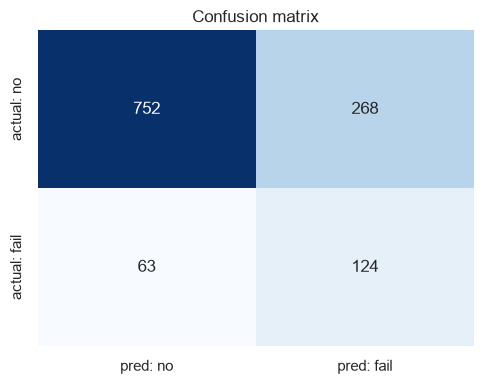

In [6]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["pred: no", "pred: fail"],
            yticklabels=["actual: no", "actual: fail"], ax=ax)
ax.set_title("Confusion matrix")
plt.tight_layout()

tn, fp, fn, tp = cm.ravel()
print(f"caught {tp} of {tp+fn} real failures  (recall {tp/(tp+fn):.1%})")
print(f"{fp} false alarms out of {tn+fp} healthy turbines")

## Moving the threshold

The model outputs probabilities. `predict()` applies a 0.5 cut-off, which is a
convention, not a decision. Here is what other cut-offs would cost and buy.

In [7]:
proba = model.predict_proba(X_test)[:, 1]

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({
        "threshold": t,
        "recall": round(tp / (tp + fn), 3),
        "precision": round(tp / (tp + fp), 3) if (tp + fp) else 0.0,
        "missed_failures": fn,
        "false_alarms": fp,
    })
pd.DataFrame(rows)

,threshold,recall,precision,missed_failures,false_alarms
0,0.2,0.930,0.184,13,770
1,0.3,0.845,0.226,29,542
2,0.4,0.743,0.266,48,384
3,0.5,0.663,0.316,63,268
4,0.6,0.578,0.391,79,168
5,0.7,0.444,0.519,104,77


**This table is the actual deliverable of a modelling exercise**, more than any
single score. It converts a model into a business decision: for each threshold, how
many real failures you miss and how many crews you send out for nothing.

Choosing a row requires knowing what a missed failure costs versus an unnecessary
inspection — intake sheet question 6. The model cannot answer that, and neither can
the data scientist alone.

## Cross-validation, done safely

In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="recall")
print(f"recall across 5 folds: {scores.round(3)}")
print(f"mean {scores.mean():.3f}  sd {scores.std():.3f}")

recall across 5 folds: [0.691 0.787 0.673 0.678 0.738]
mean 0.713  sd 0.043


Because the whole pipeline is passed to `cross_val_score`, imputation and scaling
are refitted inside every fold. Had you scaled beforehand, every fold would have been
contaminated and this number would be quietly optimistic.

---

## Block 1 complete

You have taken raw, messy data and produced a defensible, leakage-free modelling
setup with a decision table at the end.

**The habits worth keeping:**

1. Survey before fixing
2. Compute the trivial baseline before reading any score
3. Ask of every feature: would I have this at prediction time?
4. Split before fitting anything at all
5. Put preprocessing in a pipeline so leakage is structurally hard
6. Report a threshold table, not a single number

Block 2 replaces logistic regression with trees, ensembles and neural networks — on
this same pipeline, so the comparison is honest.

## Your turn

1. Add `last_inspector` as a categorical feature. Does recall improve? Should you
   keep it? (Think about what it would mean if it helped.)
2. Set `class_weight=None` and compare. Which metric moves most?
3. Pick a threshold and write one sentence defending it to an operations manager.